# FXS / 03g — Holding time: quick moves or sustained ones? (EURUSD-01, EURUSD-02, USDJPY-01, USDJPY-02, 2016 → 2026)

Question (Iván, 2026-11-10): with the entry fixed at each structure's start time, how does the **expected result per trade** change if the trade is held for 5, 10, 15 … minutes, up to **1.5 × the base holding time**? No stop, no take-profit.

| Structure | Entry | Base hold | Holds tested |
|---|---|---|---|
| EURUSD-01 | buy 01:15 UTC | 120 min | 5 → 180 min |
| EURUSD-02 | sell 04:00 New York | 240 min | 5 → 360 min |
| USDJPY-01 | sell 00:55 UTC (09:55 Tokyo) | 60 min | 5 → 90 min |
| USDJPY-02 | buy 00:25 UTC (09:25 Tokyo) | 30 min | 5 → 45 min |

How to read the curves (net pips per trade against minutes held):
- **Rises quickly, then flat:** the move happens early; holding longer adds only noise.
- **Keeps rising to the base hold:** a sustained drift; the exit time matters.
- **Peaks, then falls:** the move reverses; holding past the peak gives it back.

Every trade: entry and exit at the quoted bid/ask (Dukascopy spread × `SPREAD_FACTOR`), commission `COMMISSION_PER_LOT` per lot round trip. Shown per period: 2016–2020 (in sample), 2021–2025, 2026 (seen). Descriptive: a "best" holding time read off these curves is chosen after seeing the data.

In [1]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

COMMISSION_PER_LOT = 3.0
SPREAD_FACTOR = 0.9
STEP = 5
IDS = ["EURUSD-01", "EURUSD-02", "USDJPY-01", "USDJPY-02"]
FROZEN = {"EURUSD-01": ("UTC", 75, 195, 1), "EURUSD-02": ("NY", 660, 900, -1),
          "USDJPY-01": ("UTC", 55, 115, -1), "USDJPY-02": ("UTC", 25, 55, 1)}
WINDOWS = ((dt.date(2016, 1, 1), dt.date(2020, 12, 31), "discovery"), (dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"),
           (dt.date(2026, 1, 1), dt.date(2026, 11, 6), "holdout"))
PERIODS = {"2016-2020 (in sample)": (2016, 2020), "2021-2025": (2021, 2025), "2026": (2026, 2026)}

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs03g_")
    os.environ.pop("DUKASCOPY_DIR", None)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
BRANCH = Path.cwd().parent
OUT = Path.cwd() / ("03g_synthetic" if SYNTHETIC else "03g"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 60)

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for i, p in enumerate(("EURUSD", "USDJPY")):
        F.write_synthetic_candles(base, p, dt.date(2015, 12, 28), dt.date(2026, 11, 6), seed=21 + i, drift_bps=-3.0 if p == "EURUSD" else 0.0,
                                  drift_ny=(4, 6), price=150.0 if p.endswith("JPY") else 1.10)
    cand = pd.DataFrame([{"id": k, "pair": k[:6], "clock": c, "start": s, "end": e, "direction": d} for k, (c, s, e, d) in FROZEN.items()])
else:
    cand = F.load_frozen_candidates(BRANCH).query("id in @IDS").reset_index(drop=True)
for _, r in cand.iterrows():
    assert (r["clock"], int(r["start"]), int(r["end"]), int(r["direction"])) == FROZEN[r["id"]], f"{r['id']} is not the frozen rule"
cand = cand.set_index("id").loc[IDS].reset_index()

## 1. Net pips for every holding time, every day

In [3]:
rows = []
for (pair, clock), grp in cand.groupby(["pair", "clock"]):
    for a, b, stage in WINDOWS:
        p = F.load_panels([pair], a, b, stage, cfg, clocks=(clock,))[(pair, clock)]
        mid = 0.5 * (p.bid + p.ask)
        half = 0.5 * (p.ask - p.bid) * SPREAD_FACTOR
        bid, ask = mid - half, mid + half
        pip = F.pip_size(pair)
        years = p.years
        for _, r in grp.iterrows():
            s, base, d = int(r["start"]), int(r["end"]) - int(r["start"]), int(r["direction"])
            holds = np.arange(STEP, int(12 * base) + 1, STEP)
            holds = holds[s + holds <= F.SLOTS]
            entry = ask[:, s] if d > 0 else bid[:, s]
            comm_pips = F.bps_to_pips(F.commission_bps_per_lot(pair, COMMISSION_PER_LOT), mid[:, s], pair)
            for h in holds:
                exit_ = bid[:, s + h] if d > 0 else ask[:, s + h]
                net = (exit_ - entry) * d / pip - comm_pips
                rows.append(pd.DataFrame({"structure": r["id"], "hold": int(h), "base": base, "year": years, "net_pips": net,
                                          "mid_pips": (mid[:, s + h] - mid[:, s]) * d / pip}))
H = pd.concat(rows, ignore_index=True)
H["period"] = None
for name, (a, b) in PERIODS.items():
    H.loc[H["year"].between(a, b), "period"] = name
print(H.groupby("structure")["hold"].agg(["min", "max", "nunique"]))

           min   max  nunique
structure                    
EURUSD-01    5  1365      273
EURUSD-02    5   780      156
USDJPY-01    5   720      144
USDJPY-02    5   360       72


## 2. Mean net pips per trade by holding time (± 2 standard errors)

Dashed line: the base holding time. Grey line: the same at the mid, before spread and commission.

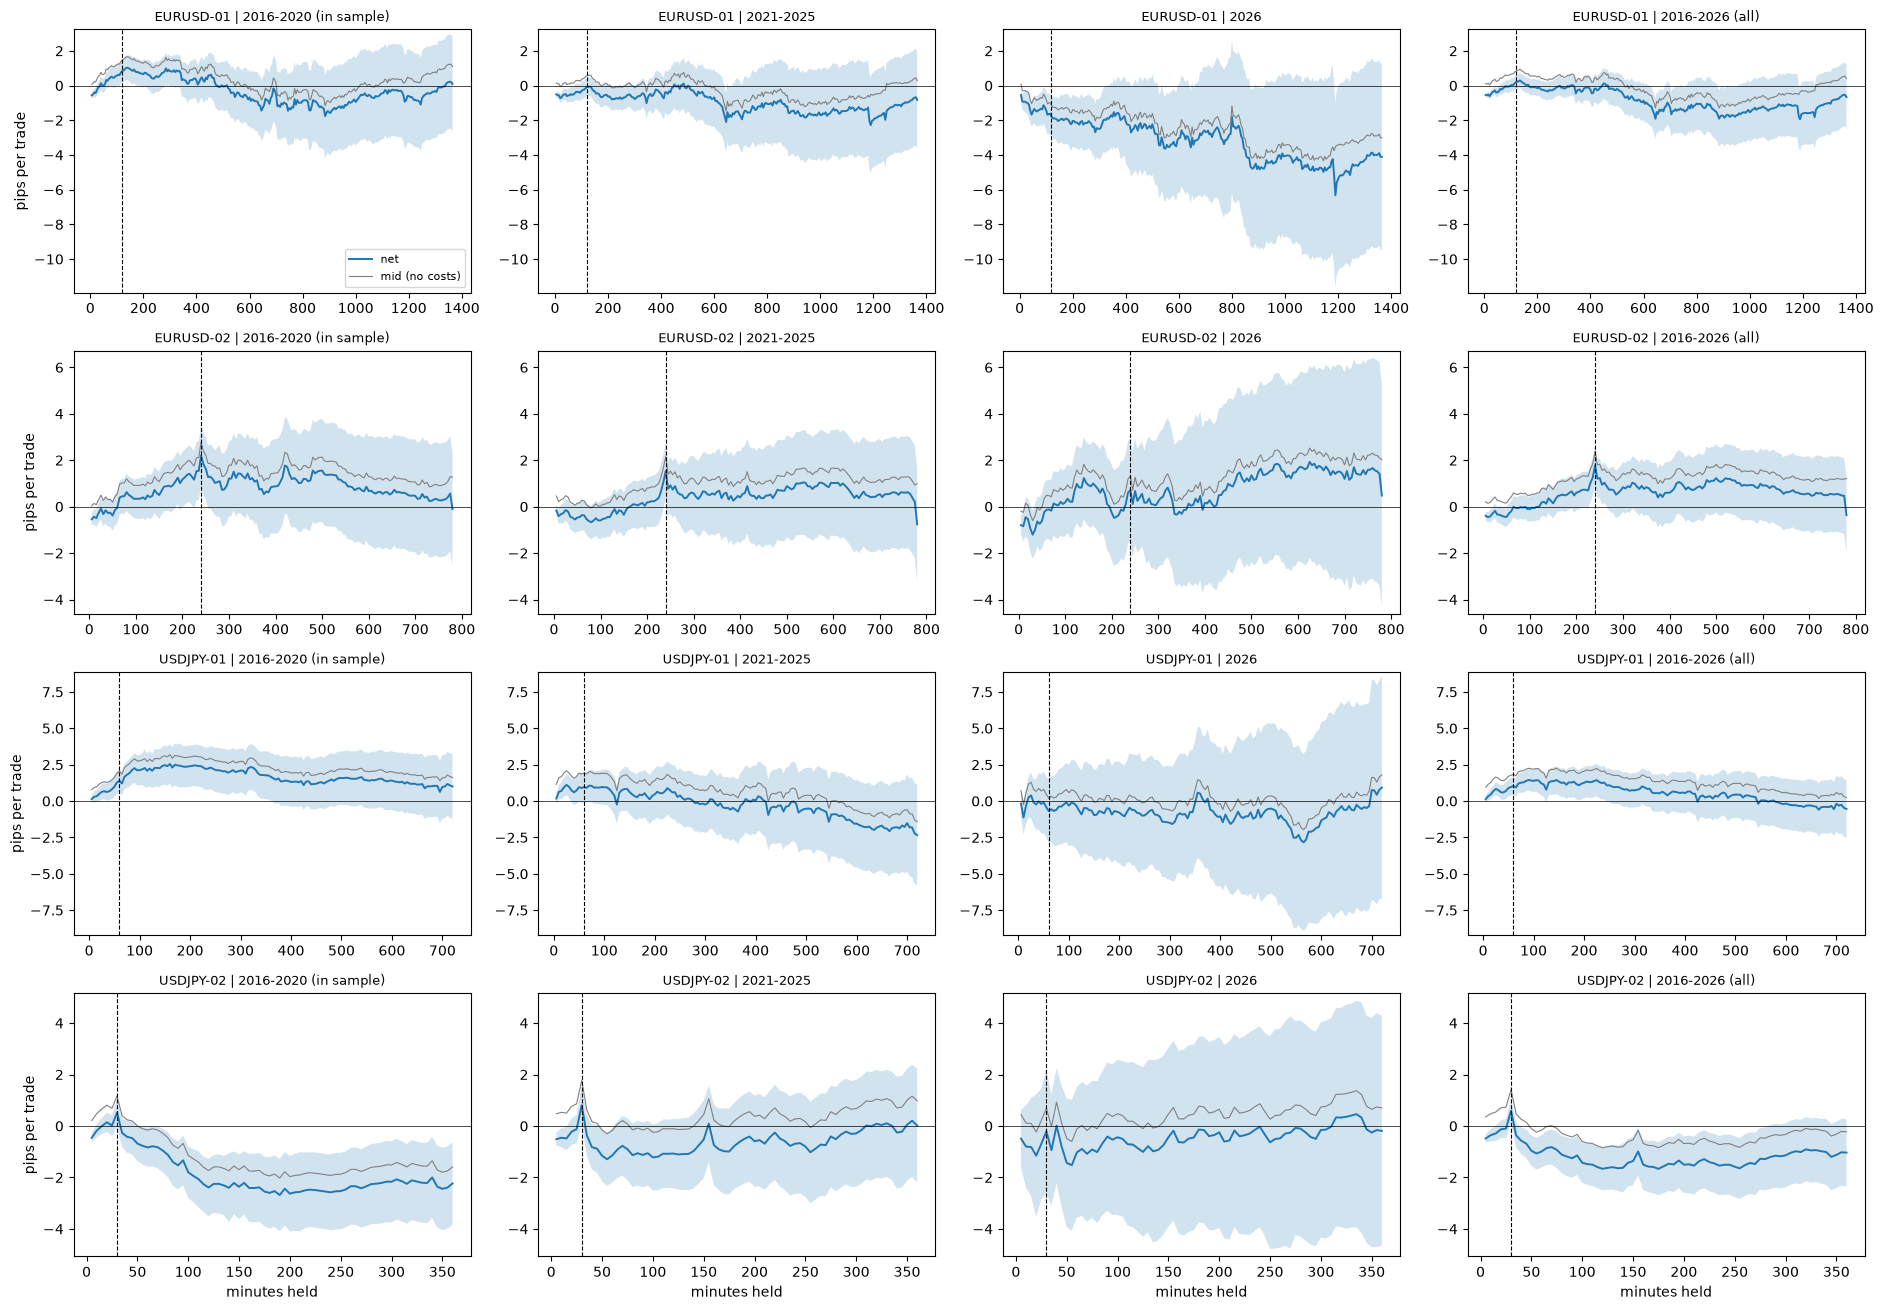

In [4]:
def agg(x):
    n = len(x); m = x["net_pips"].mean(); se = x["net_pips"].std() / np.sqrt(n)
    return pd.Series({"n": n, "net_pips": m, "se": se, "t": m / se if se > 0 else np.nan, "win_rate": (x["net_pips"] > 0).mean(),
                      "mid_pips": x["mid_pips"].mean(), "swing_pips": x["net_pips"].std()})
S = H.groupby(["structure", "period", "hold"]).apply(agg).reset_index()
S_all = H.groupby(["structure", "hold"]).apply(agg).reset_index().assign(period="2016-2026 (all)")
S = pd.concat([S, S_all], ignore_index=True)
S.to_csv(OUT / "03g_holding_curves.csv", index=False)
plist = list(PERIODS) + ["2016-2026 (all)"]
fig, axes = plt.subplots(len(IDS), len(plist), figsize=(19, 3.3 * len(IDS)), sharex="row")
for i, sid in enumerate(IDS):
    base = int(H.loc[H["structure"] == sid, "base"].iloc[0])
    lo = S.loc[S["structure"] == sid, "net_pips"] - 2 * S.loc[S["structure"] == sid, "se"]
    hi = S.loc[S["structure"] == sid, "net_pips"] + 2 * S.loc[S["structure"] == sid, "se"]
    ylim = (float(lo.min()) - 0.3, float(hi.max()) + 0.3)
    for j, per in enumerate(plist):
        ax = axes[i, j]
        c = S[(S["structure"] == sid) & (S["period"] == per)]
        ax.fill_between(c["hold"], c["net_pips"] - 2 * c["se"], c["net_pips"] + 2 * c["se"], alpha=0.2)
        ax.plot(c["hold"], c["net_pips"], lw=1.4, label="net")
        ax.plot(c["hold"], c["mid_pips"], color="grey", lw=0.8, label="mid (no costs)")
        ax.axhline(0, color="black", lw=0.5); ax.axvline(base, color="black", ls="--", lw=0.8)
        ax.set_ylim(*ylim); ax.set_title(f"{sid} | {per}", fontsize=9)
        if j == 0:
            ax.set_ylabel("pips per trade")
        if i == len(IDS) - 1:
            ax.set_xlabel("minutes held")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "03g_holding_curves.png", dpi=110); plt.show()

## 3. Tables: net pips per trade at each holding time

In [5]:
for sid in IDS:
    t = S[S["structure"] == sid].pivot(index="hold", columns="period", values="net_pips")[plist]
    tt = S[S["structure"] == sid].pivot(index="hold", columns="period", values="t")[plist].add_suffix(" t")
    base = int(H.loc[H["structure"] == sid, "base"].iloc[0])
    print(f"\n=== {sid} (base hold {base} min) ===")
    display(pd.concat([t.round(2), tt.round(1)], axis=1))


=== EURUSD-01 (base hold 120 min) ===


period,2016-2020 (in sample),2021-2025,2026,2016-2026 (all),2016-2020 (in sample) t,2021-2025 t,2026 t,2016-2026 (all) t
hold,,,,,,,,
5,-0.57,-0.51,-0.56,-0.54,-7.9,-7.7,-2.9,-11.4
10,-0.51,-0.56,-0.91,-0.57,-4.7,-6.0,-3.9,-8.2
15,-0.40,-0.57,-0.94,-0.52,-3.1,-5.2,-3.6,-6.5
20,-0.43,-0.73,-0.93,-0.61,-3.2,-5.7,-3.1,-6.8
25,-0.26,-0.68,-0.97,-0.51,-1.6,-4.8,-3.1,-5.0
...,...,...,...,...,...,...,...,...
1345,0.17,-0.84,-4.00,-0.63,0.1,-0.6,-1.5,-0.7
1350,0.20,-0.75,-3.98,-0.56,0.1,-0.5,-1.5,-0.6
1355,0.22,-0.70,-3.90,-0.53,0.2,-0.5,-1.5,-0.6



=== EURUSD-02 (base hold 240 min) ===


period,2016-2020 (in sample),2021-2025,2026,2016-2026 (all),2016-2020 (in sample) t,2021-2025 t,2026 t,2016-2026 (all) t
hold,,,,,,,,
5,-0.55,-0.17,-0.80,-0.39,-4.3,-1.3,-3.9,-4.7
10,-0.44,-0.41,-0.84,-0.45,-2.7,-2.5,-2.6,-4.1
15,-0.49,-0.33,-0.45,-0.41,-2.5,-1.6,-1.1,-3.1
20,-0.27,-0.28,-0.54,-0.30,-1.3,-1.3,-1.2,-2.0
25,-0.09,-0.15,-0.94,-0.18,-0.4,-0.6,-1.9,-1.1
...,...,...,...,...,...,...,...,...
760,0.30,0.62,1.66,0.55,0.2,0.5,0.7,0.7
765,0.32,0.54,1.57,0.52,0.3,0.4,0.7,0.6
770,0.41,0.37,1.52,0.48,0.3,0.3,0.6,0.6



=== USDJPY-01 (base hold 60 min) ===


period,2016-2020 (in sample),2021-2025,2026,2016-2026 (all),2016-2020 (in sample) t,2021-2025 t,2026 t,2016-2026 (all) t
hold,,,,,,,,
5,0.14,0.17,-0.18,0.13,1.1,1.0,-0.4,1.3
10,0.29,0.63,-1.13,0.33,1.4,2.6,-1.9,2.2
15,0.33,0.70,-0.33,0.45,1.6,2.4,-0.5,2.6
20,0.49,0.94,0.25,0.68,2.1,2.8,0.4,3.5
25,0.63,1.11,0.39,0.83,2.3,3.1,0.5,3.8
...,...,...,...,...,...,...,...,...
700,0.97,-1.52,0.75,-0.19,0.9,-0.9,0.2,-0.2
705,1.00,-1.80,0.73,-0.31,0.9,-1.1,0.2,-0.3
710,1.17,-1.81,0.43,-0.26,1.1,-1.1,0.1,-0.3



=== USDJPY-02 (base hold 30 min) ===


period,2016-2020 (in sample),2021-2025,2026,2016-2026 (all),2016-2020 (in sample) t,2021-2025 t,2026 t,2016-2026 (all) t
hold,,,,,,,,
5,-0.46,-0.52,-0.49,-0.49,-5.2,-4.2,-0.9,-5.9
10,-0.18,-0.46,-0.80,-0.36,-1.4,-2.5,-1.0,-3.0
15,-0.00,-0.48,-0.82,-0.29,-0.0,-2.1,-0.9,-1.9
20,0.14,-0.22,-1.16,-0.13,0.8,-0.9,-1.0,-0.7
25,0.02,-0.12,-0.70,-0.10,0.1,-0.4,-0.6,-0.6
...,...,...,...,...,...,...,...,...
340,-2.00,-0.25,0.32,-1.01,-2.5,-0.2,0.1,-1.6
345,-2.36,-0.22,-0.13,-1.20,-3.0,-0.2,-0.1,-1.9
350,-2.44,0.04,-0.26,-1.12,-3.0,0.0,-0.1,-1.7


## 4. Summary per structure and period

Peak holding time and its result (chosen after the fact, so optimistic), the base hold, and how much of the peak is kept at 1.5 × base. `share of peak reached by` = first holding time at which half of the peak net is reached: a small number means a quick move.

In [6]:
summ = []
for sid in IDS:
    base = int(H.loc[H["structure"] == sid, "base"].iloc[0])
    for per in plist:
        c = S[(S["structure"] == sid) & (S["period"] == per)].set_index("hold")
        pk = c["net_pips"].idxmax()
        half_at = c.index[c["net_pips"] >= 0.5 * c.loc[pk, "net_pips"]][0] if c.loc[pk, "net_pips"] > 0 else np.nan
        summ.append({"structure": sid, "period": per, "base hold": base, "net at base": c.loc[base, "net_pips"] if base in c.index else np.nan,
                     "peak hold": pk, "net at peak": c.loc[pk, "net_pips"], "t at peak": c.loc[pk, "t"],
                     "half of peak reached by (min)": half_at, "net at 1.5x base": c["net_pips"].iloc[-1],
                     "swing at base (st.dev. pips)": c.loc[base, "swing_pips"] if base in c.index else np.nan})
summ = pd.DataFrame(summ)
display(summ.round(2)); summ.to_csv(OUT / "03g_summary.csv", index=False)

,structure,period,base hold,net at base,peak hold,net at peak,t at peak,half of peak reached by (min),net at 1.5x base,swing at base (st.dev. pips)
0,EURUSD-01,2016-2020 (in sample),120,0.84,140,1.02,2.84,80.0,0.09,11.76
1,EURUSD-01,2021-2025,120,-0.10,485,0.12,0.16,450.0,-0.83,9.56
2,EURUSD-01,2026,120,-1.79,5,-0.56,-2.92,NaN,-4.11,8.72
3,EURUSD-01,2016-2026 (all),120,0.20,135,0.29,1.37,120.0,-0.66,10.60
4,EURUSD-02,2016-2020 (in sample),240,2.20,240,2.20,3.37,190.0,-0.11,23.53
5,EURUSD-02,2021-2025,240,1.54,240,1.54,2.59,235.0,-0.76,21.36
6,EURUSD-02,2026,240,0.71,625,1.93,0.94,125.0,0.48,16.47
7,EURUSD-02,2016-2026 (all),240,1.78,240,1.78,4.28,230.0,-0.36,22.05
8,USDJPY-01,2016-2020 (in sample),60,1.40,160,2.55,3.75,55.0,1.01,14.14
9,USDJPY-01,2021-2025,60,0.97,25,1.11,3.08,10.0,-2.34,18.64


## 5. Pips per hour held (net at each hold ÷ hours held)

If most of the result comes early, pips per hour are highest for short holds and fall as the hold lengthens.

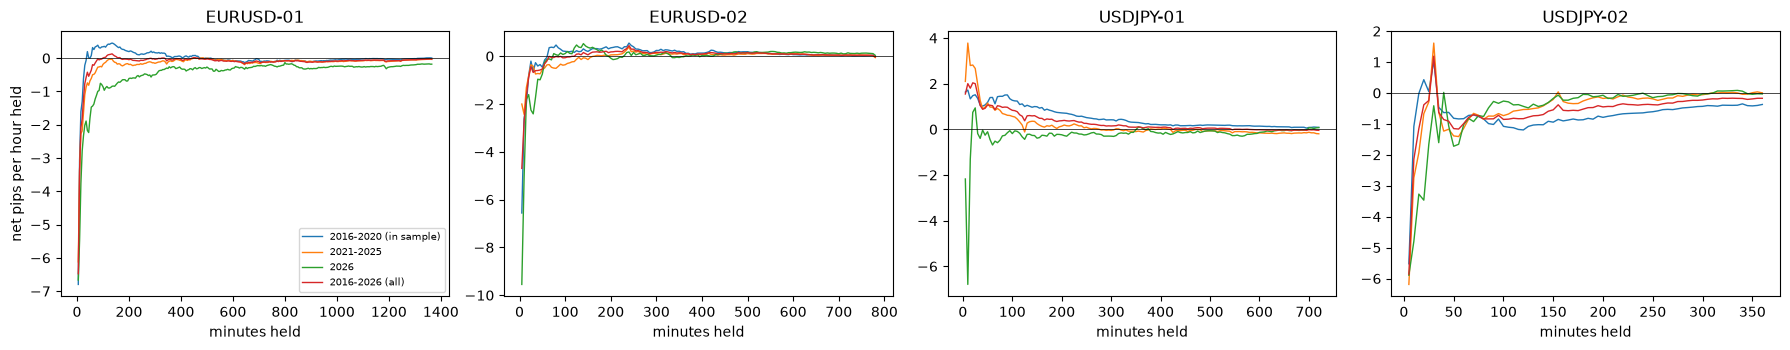

In [7]:
S["pips_per_hour"] = S["net_pips"] / (S["hold"] / 60)
fig, axes = plt.subplots(1, len(IDS), figsize=(18, 3.6))
for ax, sid in zip(axes, IDS):
    for per in plist:
        c = S[(S["structure"] == sid) & (S["period"] == per)]
        ax.plot(c["hold"], c["pips_per_hour"], lw=1, label=per)
    ax.axhline(0, color="black", lw=0.5); ax.set_title(sid); ax.set_xlabel("minutes held")
axes[0].set_ylabel("net pips per hour held"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "03g_pips_per_hour.png", dpi=110); plt.show()

In [8]:
summary = {"study": "FXS03g", "descriptive": True, "synthetic": SYNTHETIC, "structures": IDS, "step_minutes": STEP,
           "commission_usd_per_lot_rt": COMMISSION_PER_LOT, "spread_factor": SPREAD_FACTOR,
           "summary": summ.round(4).to_dict(orient="records"),
           "note": "Holding times read off these curves are chosen after seeing the data; structures picked with 2021-2025; 2026 seen."}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\FX_Intraday_Seasonality\Portfolio\03g\summary.json
